# Natural Language Processing — Lab 02
## Data Acquisition

| | |
|---|---|
| **Student** | Eman Amjad |
| **Roll Number** | FA23-BAI-013 |
| **Course** | Natural Language Processing |

This lab pulls text out of the formats it actually lives in: PDF files, Word documents, JSON APIs and HTML pages. The web activities run against the live sites, so the printed numbers reflect the pages at the time the notebook was executed.

In [1]:
# Setup  |  Eman Amjad  |  FA23-BAI-013
import json
import re
import warnings
from collections import Counter
from pathlib import Path
from urllib.parse import urljoin

warnings.filterwarnings("ignore", category=DeprecationWarning)   # PyPDF2 3.x announces its move to pypdf

import PyPDF2
import docx
import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 120)

DATA_DIR = Path("data/lab02")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Some sites block the default python-requests agent, and requests has no
# timeout by default, so every web call in this lab goes through this helper.
HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}

def fetch(url, **kwargs):
    response = requests.get(url, headers=HEADERS, timeout=30, **kwargs)
    response.raise_for_status()
    return response

print("PyPDF2       :", PyPDF2.__version__)
print("pandas       :", pd.__version__)
print("requests     :", requests.__version__)
print("Data folder  :", DATA_DIR.as_posix())

PyPDF2       : 3.0.1
pandas       : 3.1.0
requests     : 2.34.2
Data folder  : data/lab02


---

# Preparing the Sample Files

The manual reads a `sample.pdf` and a `sample.docx` that were not supplied with the lab, so the two cells below create them under `data/lab02/`. The PDF is a four-page set of course notes with a running header, page numbers and the punctuation (quotes, hyphens, dashes) that Home Activity 1 has to clean. The Word file uses Word's built-in heading styles, which is what Activity 2 relies on.

In [2]:
# Sample PDF  |  Eman Amjad  |  FA23-BAI-013
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, PageBreak

pdf_sections = [
    ("1. Why Data Acquisition Comes First", [
        "Every natural language processing system starts with text, and that text rarely arrives in a clean, ready-to-use form. "
        "Customer emails, scanned contracts, news articles, product reviews and research papers are all stored in different formats, "
        "and each format hides the words behind its own layer of structure.",
        "A model can only be as good as the data it is trained on. If the acquisition step silently drops pages, merges columns "
        "or keeps navigation menus as if they were content, every later step - tokenization, tagging, classification - inherits "
        "those mistakes. For this reason acquisition is treated as an engineering task of its own, not as a quick preliminary.",
        "In practice a data scientist spends a surprising share of a project on this stage. Surveys of industry teams often "
        "describe data preparation as the most time-consuming part of building a model, and the first half of that work is simply "
        "getting the text out of where it lives.",
    ]),
    ("2. Text Inside PDF Files", [
        "A PDF page is a set of drawing instructions. Each glyph is placed at an x and y position with a font, and the file has no "
        "native idea of a word, a sentence or a paragraph. Extraction libraries rebuild the reading order by walking the content "
        "stream and grouping glyphs that sit close together.",
        "This reconstruction works well for single-column reports like this one, but it struggles with two-column papers, tables "
        "and footnotes. Lines from the left and right columns can be interleaved, and headers or page numbers appear in the middle "
        "of the extracted text.",
        "Scanned documents are a separate problem. A scanned page is an image, so a text extractor returns an empty string - the "
        "words only exist as pixels. Recovering them needs optical character recognition, which is outside the scope of a "
        "plain PDF parser.",
        "Because of these issues, extracted PDF text should always be treated as \u201craw\u201d input. Removing stray line breaks, "
        "re-joining hyphenated words and filtering repeated headers are routine follow-up steps.",
    ]),
    ("3. Word Documents and Their Structure", [
        "A .docx file is a ZIP archive of XML parts. Each paragraph is its own XML node, and each node carries a style name such as "
        "Heading 1 or Normal. That style name is what lets a program separate headings from body text without guessing from font size.",
        "The approach has a weakness: authors who make a line bold and large instead of applying a heading style produce a document "
        "that looks structured but is not. A parser that trusts style names will classify those lines as ordinary body text.",
    ]),
    ("4. JSON APIs", [
        "Many organisations publish data through web APIs that answer an HTTP request with JSON. A JSON object maps directly to a "
        "Python dictionary and a JSON array maps to a list, so parsing is deterministic and needs no custom logic.",
        "APIs are designed for machines. Their field names are documented and stable, which makes them far less fragile than "
        "scraping. When an API exists for a dataset it should be the first choice - it is faster, cleaner and usually allowed by the "
        "provider\u2019s terms of use.",
        "Real APIs return results in pages. A request might return the first thirty records together with a total count, and the "
        "client must ask for the remaining pages using parameters such as limit and skip. Forgetting this step is a common reason "
        "for datasets that are smaller than expected.",
    ]),
    ("5. Scraping HTML Pages", [
        "HTML is a tree of nested tags. Elements such as a book title or a quote are usually marked up with the same tag and class "
        "on every repetition, which is what makes structured scraping possible.",
        "Tools like BeautifulSoup search this tree by tag name and attribute rather than by scanning raw text with regular "
        "expressions. Tree-based extraction keeps working when spacing or attribute order changes, whereas a regular expression "
        "breaks silently.",
        "Responsible scraping means reading the site\u2019s robots.txt, sending a clear user-agent, adding a delay between requests "
        "and never collecting personal data without permission. A scraper that floods a small server is not just rude - it can be "
        "blocked or cause real harm.",
    ]),
    ("6. Cleaning the Acquired Text", [
        "Once text has been extracted, a short cleaning pass makes it usable: lower-casing, removing punctuation, normalising "
        "whitespace and fixing encoding errors. The exact steps depend on the task. Sentiment analysis may keep exclamation marks, "
        "while topic modelling usually removes them.",
        "Counting word frequencies right after cleaning is a quick sanity check. If the most frequent tokens are page numbers or "
        "fragments of a running header, the extraction step needs another look before any model is trained on the data.",
        "Good acquisition code is also repeatable. Saving the raw text alongside the cleaned version, recording the source URL and "
        "the date of collection, and keeping the scripts under version control make it possible to rebuild the corpus later.",
    ]),
]

def draw_page_furniture(canvas, document):
    # Running header and page number: the kind of noise real PDFs carry
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawString(2 * cm, A4[1] - 1.3 * cm, "AIC365 Natural Language Processing - Data Acquisition Notes")
    canvas.drawRightString(A4[0] - 2 * cm, 1.2 * cm, f"Page {document.page}")
    canvas.restoreState()

pdf_path = DATA_DIR / "sample.pdf"
styles = getSampleStyleSheet()
story = [Paragraph("Data Acquisition for NLP: Course Notes", styles["Title"]), Spacer(1, 0.4 * cm)]
for i, (heading, paragraphs) in enumerate(pdf_sections):
    if i in (2, 3, 5):                   # force a few page breaks so the file is clearly multi-page
        story.append(PageBreak())
    story.append(Paragraph(heading, styles["Heading2"]))
    for text in paragraphs:
        story.append(Paragraph(text, styles["BodyText"]))
        story.append(Spacer(1, 0.25 * cm))

SimpleDocTemplate(str(pdf_path), pagesize=A4, topMargin=2.2 * cm, bottomMargin=2 * cm,
                  title="Data Acquisition Notes", author="Eman Amjad").build(
    story, onFirstPage=draw_page_furniture, onLaterPages=draw_page_furniture)

print(f"Created {pdf_path}  ({pdf_path.stat().st_size:,} bytes, {len(PyPDF2.PdfReader(str(pdf_path)).pages)} pages)")

Created data\lab02\sample.pdf  (7,488 bytes, 4 pages)


In [3]:
# Sample DOCX  |  Eman Amjad  |  FA23-BAI-013
docx_path = DATA_DIR / "sample.docx"
document = docx.Document()

document.add_heading("Field Report: Building a Local News Corpus", level=0)   # style "Title"
document.add_paragraph("Prepared for the NLP lab, Department of Computer Science.")

document.add_heading("Background", level=1)
document.add_paragraph(
    "Most public NLP datasets are built from English news and encyclopedia text. For a project on regional reporting we "
    "needed a smaller corpus of local news, collected from city newspapers, community radio transcripts and municipal "
    "press releases over a period of three months.")
document.add_paragraph(
    "The goal was not size but variety: the corpus had to include formal announcements, informal interviews and short "
    "breaking-news updates so that later classifiers would see every register.")

document.add_heading("Sources", level=1)
document.add_heading("Newspapers", level=2)
document.add_paragraph(
    "Three city newspapers offered RSS feeds. Each feed item linked to a full article page, which was downloaded once, "
    "stored as raw HTML and parsed with BeautifulSoup to remove advertisements, navigation menus and comment sections. "
    "About 4,200 articles were collected this way, averaging roughly 550 words each.")
document.add_heading("Radio Transcripts", level=2)
document.add_paragraph(
    "Community radio stations shared transcripts as Word documents. These were the cleanest source because each speaker "
    "turn was a separate paragraph with a consistent style.")
document.add_paragraph(
    "Some older transcripts, however, used bold text instead of real heading styles, so the section titles had to be "
    "recovered by hand.")
document.add_heading("Press Releases", level=2)
document.add_paragraph(
    "Municipal press releases were only available as PDFs. Single-column releases extracted cleanly, but releases with "
    "a two-column layout produced interleaved lines and had to be checked manually. Around fifteen percent of the PDFs "
    "were scanned images with no text layer at all and were set aside for a later OCR pass.")

document.add_heading("Cleaning Steps", level=1)
document.add_paragraph(
    "All text was converted to UTF-8, repeated headers and footers were removed, and hyphenated words split across line "
    "breaks were joined again. Duplicate articles, which appeared when the same story was published by two outlets, were "
    "detected with a simple hash of the first two hundred characters and dropped.")
document.add_paragraph("Short updates under twenty words were kept in a separate file.")

document.add_heading("Lessons Learned", level=1)
document.add_paragraph(
    "The biggest surprise was how much time went into acquisition compared with modelling. Writing a separate extractor "
    "for every format, logging which files failed, and keeping the raw downloads so that every cleaning step could be "
    "repeated turned out to be more valuable than any single clever trick.")
document.add_paragraph(
    "A second lesson was to prefer official APIs whenever they exist. The one newspaper that offered a JSON API needed "
    "ten lines of code; the two that did not needed several hundred lines of scraping logic that broke twice when their "
    "page layouts changed.")
document.add_paragraph("Next step: label a sample of 1,000 articles by topic.")

document.save(docx_path)
print(f"Created {docx_path}  ({docx_path.stat().st_size:,} bytes, {len(document.paragraphs)} paragraphs)")

Created data\lab02\sample.docx  (37,982 bytes, 20 paragraphs)


---

# In-Lab Activities

**Activity 1** — Open a PDF file in Python and extract the raw text from all of its pages into a single string.

In [4]:
# Activity 1  |  Eman Amjad  |  FA23-BAI-013
pdf_file = DATA_DIR / "sample.pdf"

try:
    # PDF is a binary format, so the file must be opened in "rb" mode
    with open(pdf_file, "rb") as file:
        reader = PyPDF2.PdfReader(file)
        extracted_text = ""
        for page in reader.pages:
            extracted_text += page.extract_text() + "\n"

    print(f"Pages read        : {len(reader.pages)}")
    print(f"Characters total  : {len(extracted_text):,}")
    print("\n--- first 1000 characters ---")
    print(extracted_text[:1000])
except FileNotFoundError:
    print(f"File '{pdf_file}' not found.")

Pages read        : 4
Characters total  : 5,157

--- first 1000 characters ---
AIC365 Natural Language Processing - Data Acquisition Notes
Page 1
Data Acquisition for NLP: Course Notes
1. Why Data Acquisition Comes First
Every natural language processing system starts with text, and that text rarely arrives in a clean,
ready-to-use form. Customer emails, scanned contracts, news articles, product reviews and
research papers are all stored in different formats, and each format hides the words behind its own
layer of structure.
A model can only be as good as the data it is trained on. If the acquisition step silently drops pages,
merges columns or keeps navigation menus as if they were content, every later step - tokenization,
tagging, classification - inherits those mistakes. For this reason acquisition is treated as an
engineering task of its own, not as a quick preliminary.
In practice a data scientist spends a surprising share of a project on this stage. Surveys of industry
teams ofte

All pages came back as one string. The running header ("AIC365 Natural Language Processing - Data Acquisition Notes") and the "Page N" footers are mixed into the text, and lines end where the PDF wrapped them rather than where sentences end, which is exactly the "noisy raw input" the manual warns about.

**Activity 2** — Open a Word (.docx) document in Python and extract its paragraphs into a list, separating headings from body text.

In [5]:
# Activity 2  |  Eman Amjad  |  FA23-BAI-013
try:
    doc = docx.Document(DATA_DIR / "sample.docx")

    headings = []
    body_paragraphs = []

    for para in doc.paragraphs:
        if not para.text.strip():            # skip empty paragraphs
            continue
        # The heading/body decision comes from the paragraph's style name, not its font
        if para.style.name.startswith("Heading"):
            headings.append(para.text)
        else:
            body_paragraphs.append(para.text)

    print("Total Headings       :", len(headings))
    print("Total Body Paragraphs:", len(body_paragraphs))
    print("\nHeadings:")
    for h in headings:
        print("  -", h)

    style_counts = Counter(p.style.name for p in doc.paragraphs if p.text.strip())
    print("\nParagraph styles found:", dict(style_counts))
except FileNotFoundError:
    print("File 'sample.docx' not found.")

Total Headings       : 7
Total Body Paragraphs: 13

Headings:
  - Background
  - Sources
  - Newspapers
  - Radio Transcripts
  - Press Releases
  - Cleaning Steps
  - Lessons Learned

Paragraph styles found: {'Title': 1, 'Normal': 12, 'Heading 1': 4, 'Heading 2': 3}


The style-based split finds the 7 `Heading 1`/`Heading 2` paragraphs. The document title uses Word's `Title` style, which does not start with "Heading", so it lands in the body list — the same kind of misclassification the manual describes for headings that were formatted by hand instead of with a heading style.

**Activity 3** — Send a request to a public JSON API endpoint (`https://jsonplaceholder.typicode.com/users`), retrieve the response and parse it into a Python dictionary/list.

In [6]:
# Activity 3  |  Eman Amjad  |  FA23-BAI-013
url = "https://jsonplaceholder.typicode.com/users"
response = fetch(url)

print("Status code :", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

# .json() turns the JSON array into a Python list of dicts
users_data = response.json()
print("Parsed type :", type(users_data).__name__, "of", type(users_data[0]).__name__)
print("Users       :", len(users_data))

user_names = [user["name"] for user in users_data]
print("\nExtracted Users:", user_names)

# Nested objects become nested dicts, so they can be indexed directly
first = users_data[0]
print(f"\nFirst user: {first['name']} | {first['email']} | city = {first['address']['city']} "
      f"| company = {first['company']['name']}")

Status code : 200
Content type: application/json; charset=utf-8
Parsed type : list of dict
Users       : 10

Extracted Users: ['Leanne Graham', 'Ervin Howell', 'Clementine Bauch', 'Patricia Lebsack', 'Chelsey Dietrich', 'Mrs. Dennis Schulist', 'Kurtis Weissnat', 'Nicholas Runolfsdottir V', 'Glenna Reichert', 'Clementina DuBuque']

First user: Leanne Graham | Sincere@april.biz | city = Gwenborough | company = Romaguera-Crona


**Activity 4** — Fetch the raw HTML of `https://quotes.toscrape.com/`, parse it with BeautifulSoup and extract the page title and the text of every hyperlink (`<a>`).

In [7]:
# Activity 4  |  Eman Amjad  |  FA23-BAI-013
url = "https://quotes.toscrape.com/"
response = fetch(url)
print("Raw HTML length:", len(response.text), "characters")
print("First 200 chars:", response.text[:200].replace("\n", " "))

soup = BeautifulSoup(response.text, "html.parser")

page_title = soup.title.string.strip()
print("\nPage Title:", page_title)

links = soup.find_all("a")
link_texts = [link.text.strip() for link in links if link.text.strip()]

print(f"\nTotal <a> tags: {len(links)}  |  with visible text: {len(link_texts)}")
print("\nHyperlink Texts (First 10):")
print(link_texts[:10])

Raw HTML length: 11021 characters
First 200 chars: <!DOCTYPE html> <html lang="en"> <head> 	<meta charset="UTF-8"> 	<title>Quotes to Scrape</title>     <link rel="stylesheet" href="/static/bootstrap.min.css">     <link rel="stylesheet" href="/static/m

Page Title: Quotes to Scrape

Total <a> tags: 55  |  with visible text: 55

Hyperlink Texts (First 10):
['Quotes to Scrape', 'Login', '(about)', 'change', 'deep-thoughts', 'thinking', 'world', '(about)', 'abilities', 'choices']


**Activity 5** — Using BeautifulSoup on `https://books.toscrape.com/`, extract a repeated structured element (each book's title and link) into a list of dictionaries.

In [8]:
# Activity 5  |  Eman Amjad  |  FA23-BAI-013
url = "https://books.toscrape.com/"
soup = BeautifulSoup(fetch(url).text, "html.parser")

# Every book listing on the page is an <article class="product_pod">
book_elements = soup.find_all("article", class_="product_pod")

books_list = []
for book in book_elements:
    a_tag = book.h3.a
    title = a_tag["title"]                     # the visible text is truncated; the title attribute is complete
    link = url + a_tag["href"]                 # works here because hrefs are relative without a leading "/"
    assert link == urljoin(url, a_tag["href"]) # urljoin is the safe general-purpose version
    price = book.find("p", class_="price_color").text
    books_list.append({"title": title, "link": link, "price": price})

print(f"Successfully extracted {len(books_list)} books.")
print("First extracted item:", books_list[0])

books_df = pd.DataFrame(books_list)
books_df.head(10)

Successfully extracted 20 books.
First extracted item: {'title': 'A Light in the Attic', 'link': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html', 'price': 'Â£51.77'}


,title,link,price
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html,Â£51.77
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html,Â£53.74
2,Soumission,https://books.toscrape.com/catalogue/soumission_998/index.html,Â£50.10
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-objects_997/index.html,Â£47.82
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_99...,Â£54.23
5,The Requiem Red,https://books.toscrape.com/catalogue/the-requiem-red_995/index.html,Â£22.65
6,The Dirty Little Secrets of Getting Your Dream Job,https://books.toscrape.com/catalogue/the-dirty-little-secrets-of-getting-you...,Â£33.34
7,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victor...",https://books.toscrape.com/catalogue/the-coming-woman-a-novel-based-on-the-l...,Â£17.93
8,The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 19...,https://books.toscrape.com/catalogue/the-boys-in-the-boat-nine-americans-and...,Â£22.60
9,The Black Maria,https://books.toscrape.com/catalogue/the-black-maria_991/index.html,Â£52.15


All 20 `product_pod` blocks on the first page were turned into dictionaries with a complete title and an absolute link. Plain string concatenation gave the same links as `urljoin` on this site, but only because its `href` values are relative paths without a leading `/`.

---

# Home Activities

**Home Activity 1** — From a multi-page PDF, extract text from all pages, clean it (remove commas, full stops, quotation marks, hyphens and dashes), combine it into one string and report the 10 most frequent words.

In [9]:
# Home Activity 1  |  Eman Amjad  |  FA23-BAI-013
with open(DATA_DIR / "sample.pdf", "rb") as file:
    reader = PyPDF2.PdfReader(file)
    page_texts = [page.extract_text() for page in reader.pages]

for i, text in enumerate(page_texts, start=1):
    print(f"Page {i}: {len(text.split()):>4} words")

combined = " ".join(page_texts)

# Characters the activity asks to remove: , . " ' and the curly quote forms, - (hyphen), en dash and em dash
remove_chars = ",.\"'\u201c\u201d\u2018\u2019-\u2013\u2014"
cleaned = combined.translate(str.maketrans({ch: " " for ch in remove_chars}))
cleaned = re.sub(r"\s+", " ", cleaned).strip().lower()   # merge line breaks / repeated spaces

print(f"\nCharacters before cleaning: {len(combined):,}")
print(f"Characters after cleaning : {len(cleaned):,}")
print("Cleaned sample:", cleaned[:300])

words = cleaned.split()
top10 = Counter(words).most_common(10)
print(f"\nTotal words: {len(words):,}  |  unique: {len(set(words)):,}")
print("\nTop 10 most frequent words:")
for rank, (word, count) in enumerate(top10, start=1):
    print(f"{rank:>2}. {word:<12} {count}")

Page 1:  353 words
Page 2:  106 words
Page 3:  268 words
Page 4:  132 words

Characters before cleaning: 5,156
Characters after cleaning : 5,045
Cleaned sample: aic365 natural language processing data acquisition notes page 1 data acquisition for nlp: course notes 1 why data acquisition comes first every natural language processing system starts with text and that text rarely arrives in a clean ready to use form customer emails scanned contracts news articl

Total words: 863  |  unique: 442

Top 10 most frequent words:
 1. a            45
 2. the          34
 3. and          26
 4. is           20
 5. of           18
 6. text         13
 7. data         12
 8. as           12
 9. acquisition  9
10. that         9


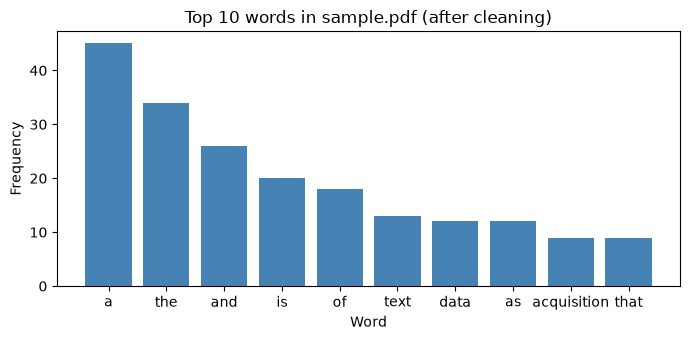

In [10]:
# Home Activity 1 (chart)  |  Eman Amjad  |  FA23-BAI-013
fig, ax = plt.subplots(figsize=(7, 3.5))
labels, counts = zip(*top10)
ax.bar(labels, counts, color="steelblue")
ax.set_title("Top 10 words in sample.pdf (after cleaning)")
ax.set_xlabel("Word")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

Most of the top 10 are function words ("a", "the", "and", "is", "of", ...), which is normal for raw counts on English prose. The content words that do make it ("text", "data", "acquisition") match the topic of the notes, and part of the "data acquisition" count comes from the running header repeated on every page, which shows why headers and footers should be filtered before counting. Removing hyphens also splits compounds such as "time-consuming" and "two-column" into separate words.

**Home Activity 2** — Open a multi-paragraph .docx file, extract all paragraphs into a list, build a DataFrame with one row per paragraph, add `word_count` and `char_count` columns, and sort by `word_count` to find the 3 longest paragraphs.

In [11]:
# Home Activity 2  |  Eman Amjad  |  FA23-BAI-013
doc = docx.Document(DATA_DIR / "sample.docx")
paragraphs = [p.text.strip() for p in doc.paragraphs if p.text.strip()]
print("Non-empty paragraphs:", len(paragraphs))

para_df = pd.DataFrame({"paragraph": paragraphs})
para_df["style"] = [p.style.name for p in doc.paragraphs if p.text.strip()]
para_df["word_count"] = para_df["paragraph"].str.split().str.len()
para_df["char_count"] = para_df["paragraph"].str.len()

para_df = para_df.sort_values("word_count", ascending=False).reset_index(drop=True)
print(para_df[["style", "word_count", "char_count"]].describe().round(1).loc[["mean", "min", "max"]])

print("\n3 longest paragraphs:")
for i, row in para_df.head(3).iterrows():
    print(f"\n#{i + 1}  ({row.word_count} words, {row.char_count} chars)")
    print(row.paragraph)

Non-empty paragraphs: 20
      word_count  char_count
mean        20.2       126.7
min          1.0         7.0
max         51.0       314.0

3 longest paragraphs:

#1  (51 words, 314 chars)
Municipal press releases were only available as PDFs. Single-column releases extracted cleanly, but releases with a two-column layout produced interleaved lines and had to be checked manually. Around fifteen percent of the PDFs were scanned images with no text layer at all and were set aside for a later OCR pass.

#2  (49 words, 307 chars)
All text was converted to UTF-8, repeated headers and footers were removed, and hyphenated words split across line breaks were joined again. Duplicate articles, which appeared when the same story was published by two outlets, were detected with a simple hash of the first two hundred characters and dropped.

#3  (48 words, 297 chars)
The biggest surprise was how much time went into acquisition compared with modelling. Writing a separate extractor for every format,

In [12]:
# Home Activity 2 (full table)  |  Eman Amjad  |  FA23-BAI-013
para_df[["paragraph", "style", "word_count", "char_count"]]

,paragraph,style,word_count,char_count
0,Municipal press releases were only available as PDFs. Single-column releases...,Normal,51,314
1,"All text was converted to UTF-8, repeated headers and footers were removed, ...",Normal,49,307
2,The biggest surprise was how much time went into acquisition compared with m...,Normal,48,297
3,Three city newspapers offered RSS feeds. Each feed item linked to a full art...,Normal,47,307
4,A second lesson was to prefer official APIs whenever they exist. The one new...,Normal,44,250
5,Most public NLP datasets are built from English news and encyclopedia text. ...,Normal,43,273
6,The goal was not size but variety: the corpus had to include formal announce...,Normal,28,186
7,Community radio stations shared transcripts as Word documents. These were th...,Normal,25,169
8,"Some older transcripts, however, used bold text instead of real heading styl...",Normal,22,130
9,Short updates under twenty words were kept in a separate file.,Normal,11,62


**Home Activity 3** — Fetch `https://dummyjson.com/users`, parse the `users` array into a DataFrame with the fields `firstName`, `age`, `address.state` and `company.department`, then group by `company.department` and report the average age per department, sorted descending.

In [13]:
# Home Activity 3  |  Eman Amjad  |  FA23-BAI-013
url = "https://dummyjson.com/users"

default_page = fetch(url).json()
print(f"Default response: {len(default_page['users'])} users of total = {default_page['total']}")

# The endpoint is paginated (30 users per page); limit=0 asks for every record at once
payload = fetch(url, params={"limit": 0}).json()
users = payload["users"]
print(f"With limit=0    : {len(users)} users")

# json_normalize flattens nested dicts into dotted column names such as address.state
users_df = pd.json_normalize(users)[["firstName", "age", "address.state", "company.department"]]
print("\n", users_df.head(), "\n")

avg_age = (users_df.groupby("company.department")["age"]
           .agg(avg_age="mean", users="count")
           .sort_values("avg_age", ascending=False)
           .round(2))
print("Average age per department (descending):")
print(avg_age)

Default response: 30 users of total = 208


With limit=0    : 208 users

   firstName  age address.state        company.department
0     Emily   29   Mississippi               Engineering
1   Michael   36       Alabama                   Support
2    Sophia   43       Alabama  Research and Development
3     James   46  Pennsylvania                   Support
4      Emma   31      Colorado           Human Resources 

Average age per department (descending):
                          avg_age  users
company.department                      
Support                     35.14     21
Research and Development    34.73     22
Training                    34.60     10
Services                    34.28     18
Engineering                 33.11     19
Legal                       33.00     23
Sales                       32.82     11
Product Management          32.41     17
Marketing                   31.96     23
Business Development        31.86      7
Human Resources             31.63     19
Accounting                  31.61     18


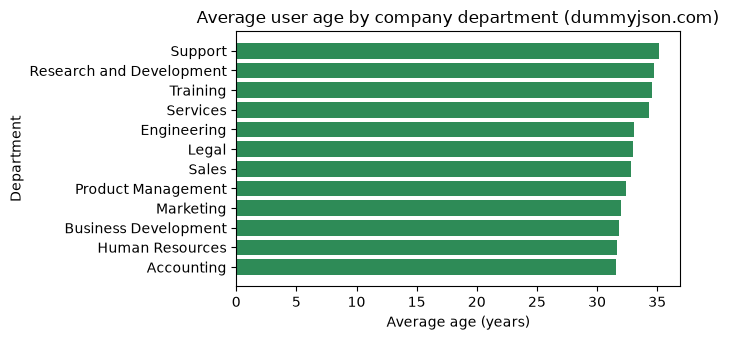

In [14]:
# Home Activity 3 (chart)  |  Eman Amjad  |  FA23-BAI-013
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(avg_age.index[::-1], avg_age["avg_age"][::-1], color="seagreen")
ax.set_title("Average user age by company department (dummyjson.com)")
ax.set_xlabel("Average age (years)")
ax.set_ylabel("Department")
plt.tight_layout()
plt.show()

The **Support** department has the highest average age (35.14 years over 21 users) and **Accounting** the lowest (31.61), so the spread across departments is under four years. The default request only returned 30 of the 208 users; without `limit=0` the averages would have been computed on a seventh of the data.

**Home Activity 4** — Fetch and parse the Wikipedia page *List of countries by population (United Nations)* with BeautifulSoup, extract the population table into a DataFrame, clean the population column (strip commas, convert the strings to integers) and report the 10 most populous countries.

In [15]:
# Home Activity 4  |  Eman Amjad  |  FA23-BAI-013
url = "https://en.wikipedia.org/wiki/List_of_countries_by_population_(United_Nations)"
soup = BeautifulSoup(fetch(url).text, "html.parser")

def cell_text(cell):
    # Drop footnote markers like [1] or [b] before reading the text
    for sup in cell.find_all("sup"):
        sup.decompose()
    return cell.get_text(" ", strip=True)

# The page has several tables (navigation boxes etc.), so pick the wikitable whose
# header row has a country column and at least one population column.
population_table = None
for table in soup.find_all("table", class_="wikitable"):
    header = [cell_text(th) for th in table.find("tr").find_all(["th", "td"])]
    if any("Country" in h for h in header) and any("Population" in h for h in header):
        population_table = table
        break

header = [cell_text(th) for th in population_table.find("tr").find_all(["th", "td"])]
rows = []
for tr in population_table.find_all("tr")[1:]:
    cells = [cell_text(td) for td in tr.find_all(["th", "td"])]
    if len(cells) == len(header):
        rows.append(cells)

pop_raw = pd.DataFrame(rows, columns=header)
print("Header found :", header)
print("Rows parsed  :", len(pop_raw))
print("\nRaw values are strings:", pop_raw.iloc[1].to_dict())

Header found : ['Country or territory', 'Population ( 1 July 2022 )', 'Population ( 1 July 2023 )', 'Change (%)', 'UN continental region', 'UN statistical subregion']
Rows parsed  : 238

Raw values are strings: {'Country or territory': 'India', 'Population ( 1 July 2022 )': '1,425,423,212', 'Population ( 1 July 2023 )': '1,438,069,596', 'Change (%)': '+0.89%', 'UN continental region': 'Asia', 'UN statistical subregion': 'Southern Asia'}


In [16]:
# Home Activity 4 (cleaning)  |  Eman Amjad  |  FA23-BAI-013
country_col = next(h for h in header if "Country" in h)
pop_cols = [h for h in header if "Population" in h]
latest_col = pop_cols[-1]                      # the most recent year on the page
print("Population column used:", latest_col)

pop_df = pop_raw[[country_col, latest_col]].rename(columns={country_col: "country", latest_col: "population"})

# Strip commas (and anything else non-numeric), then convert to integers
pop_df["population"] = pd.to_numeric(pop_df["population"].str.replace(r"[^\d]", "", regex=True),
                                     errors="coerce")
pop_df = pop_df.dropna(subset=["population"]).astype({"population": "int64"})

# The first row is the world total, not a country
pop_df = pop_df[pop_df["country"].str.lower() != "world"]
print("dtype after cleaning:", pop_df["population"].dtype, "| countries/territories:", len(pop_df))

top10_pop = pop_df.sort_values("population", ascending=False).head(10).reset_index(drop=True)
top10_pop.index += 1
top10_pop["population (millions)"] = (top10_pop["population"] / 1e6).round(1)
print("\nTop 10 most populous countries:")
top10_pop

Population column used: Population ( 1 July 2023 )
dtype after cleaning: int64 | countries/territories: 237

Top 10 most populous countries:


,country,population,population (millions)
1,India,1438069596,1438.1
2,China,1422584933,1422.6
3,United States,343477335,343.5
4,Indonesia,281190067,281.2
5,Pakistan,247504495,247.5
6,Nigeria,227882945,227.9
7,Brazil,211140729,211.1
8,Bangladesh,171466990,171.5
9,Russia,145440500,145.4
10,Mexico,129739759,129.7


The table was located by its header text rather than its position, because the page also contains navigation tables and Wikipedia's layout changes over time. After stripping commas the population column is a real `int64`, so sorting is numeric; sorted as strings, "9,..." would rank above "1,4..." billion.

**Home Activity 5** — Scrape `https://quotes.toscrape.com/tag/love/` for quote text and author into a list of dictionaries, find the author who appears most often, compute the average quote length in characters, and save the raw list to a .json file.

In [17]:
# Home Activity 5  |  Eman Amjad  |  FA23-BAI-013
import time

page_url = "https://quotes.toscrape.com/tag/love/"
love_quotes = []
pages_visited = 0

# The tag has more than one page, so follow the "Next" link until it disappears
while page_url:
    soup = BeautifulSoup(fetch(page_url).text, "html.parser")
    pages_visited += 1
    for q in soup.find_all("div", class_="quote"):
        love_quotes.append({
            "text": q.find("span", class_="text").get_text(strip=True),
            "author": q.find("small", class_="author").get_text(strip=True),
        })
    next_li = soup.find("li", class_="next")
    page_url = urljoin(page_url, next_li.a["href"]) if next_li else None
    time.sleep(0.5)   # be polite to the server

print(f"Pages visited : {pages_visited}")
print(f"Quotes scraped: {len(love_quotes)}")
print("First quote   :", love_quotes[0])

author_counts = Counter(q["author"] for q in love_quotes)
top_author, top_count = author_counts.most_common(1)[0]
print(f"\nMost frequent author: {top_author} ({top_count} quotes)")
print("Author counts:", author_counts.most_common(5))

# Length of the quote text itself, without the curly quotation marks around it
lengths = [len(q["text"].strip("\u201c\u201d")) for q in love_quotes]
print(f"\nAverage quote length: {sum(lengths) / len(lengths):.2f} characters "
      f"(shortest {min(lengths)}, longest {max(lengths)})")

json_path = DATA_DIR / "love_quotes.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(love_quotes, f, ensure_ascii=False, indent=2)
print(f"\nSaved {len(love_quotes)} quotes to {json_path}")

# Read it back to confirm the file is valid JSON
with open(json_path, encoding="utf-8") as f:
    print("Reloaded records:", len(json.load(f)))

Pages visited : 2
Quotes scraped: 14
First quote   : {'text': '“It is better to be hated for what you are than to be loved for what you are not.”', 'author': 'André Gide'}

Most frequent author: Marilyn Monroe (3 quotes)
Author counts: [('Marilyn Monroe', 3), ('Jane Austen', 2), ('André Gide', 1), ('Bob Marley', 1), ('Elie Wiesel', 1)]

Average quote length: 261.36 characters (shortest 40, longest 1082)

Saved 14 quotes to data\lab02\love_quotes.json
Reloaded records: 14


The love tag spans 2 pages, so following the "Next" link was needed to get all 14 quotes (the first page alone has 10). **Marilyn Monroe** is the most frequent author with 3 quotes, followed by Jane Austen with 2. The average quote is about 261 characters long, but the range (40 to 1,082) is wide, so a single very long quote pulls the mean up noticeably. The raw list is saved to `data/lab02/love_quotes.json`.

---

### Lab 02 complete

5 in-lab activities and 5 home activities — submitted by Eman Amjad (FA23-BAI-013).